In [1]:
!pip install mediapipe opencv-python -q

right ear 0.648 0.159
right shoulder 0.635 0.237
right hip 0.643 0.442


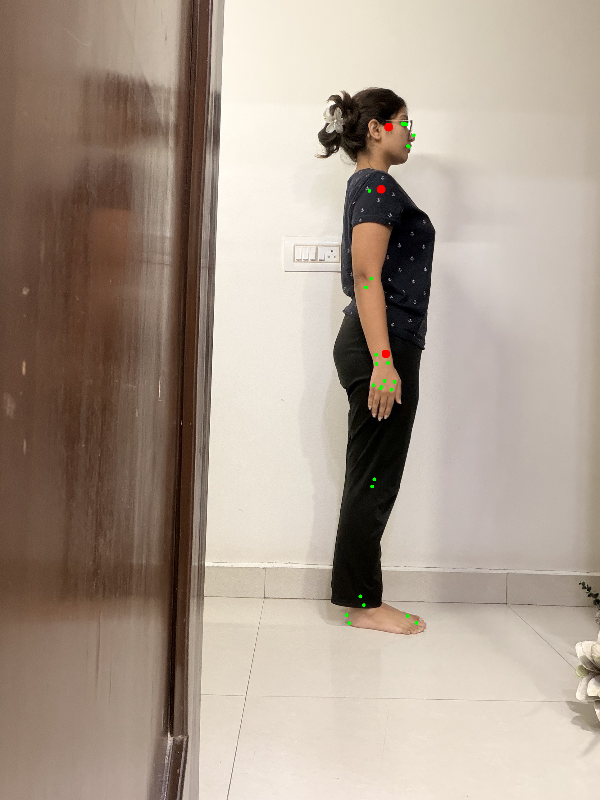

In [3]:
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task

import cv2, mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from google.colab.patches import cv2_imshow

path = "IMG_8547.jpeg"   # change this name when you test other photos
img = cv2.imread(path)

options = vision.PoseLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="pose_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE)
detector = vision.PoseLandmarker.create_from_options(options)

mp_image = mp.Image(image_format=mp.ImageFormat.SRGB,
                    data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
result = detector.detect(mp_image)

if not result.pose_landmarks:
    print("No person detected")
else:
    lm = result.pose_landmarks[0]
    h, w = img.shape[:2]
    for name, i in [("right ear", 8), ("right shoulder", 12), ("right hip", 24)]:
        print(name, round(lm[i].x, 3), round(lm[i].y, 3))
    for i, p in enumerate(lm):                       # all points, small green
        cv2.circle(img, (int(p.x * w), int(p.y * h)), 6, (0, 255, 0), -1)
    for i in (8, 12, 24):                            # the three we use, big red
        cv2.circle(img, (int(lm[i].x * w), int(lm[i].y * h)), 14, (0, 0, 255), -1)
    img = cv2.resize(img, (600, int(600 * h / w)))
    cv2_imshow(img)